In [43]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [44]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [45]:
# 1. 데이터 
# 2. 가져오기데이터 
# 3. 전처리데이터 
# 4. 분리PolynomialFeatures
#     다항추가 degree 
#     추가정규화작업
# 데이터 학습
# 규제 적용후 데이터 학습
# alpha값 변경후 데이터 학습 
# 확인데이터 예측정확도

In [46]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [47]:
# degree=20 사용
# ridge 사용, alpha값 변경해서 최성의 모델 구현

In [48]:
# 데이터 전처리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)
train_data.head(2)



,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [49]:
# PolynomialFeatures 다항추가
# degree 추가
# 정규화작업
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)


In [50]:
ss =StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [51]:

# 데이터저장
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터예측
predict = lr.predict(test_poly)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print(score,score2)
# 선그래프


0.9903183436982124 0.9714559911594145


In [52]:
alpha_list = [0.001,0.01,0.1,1,10,100]

train_score = []
test_score = []
for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)
    s1 = ridge.score(train_scaled,train_label)
    s2 = ridge.score(test_scaled,test_label)
    train_score.append(s1)
    test_score.append(s2)

train_score,test_score

([0.9897531865574942,
  0.9893635642716537,
  0.9889354346720892,
  0.9857915060511934,
  0.9776772831444959,
  0.9325445748770714],
 [0.9832623296779353,
  0.983937539450387,
  0.9856564835209132,
  0.9835057194929058,
  0.966089496112152,
  0.9399126744040402])

Text(0.5, 0, '리스트')

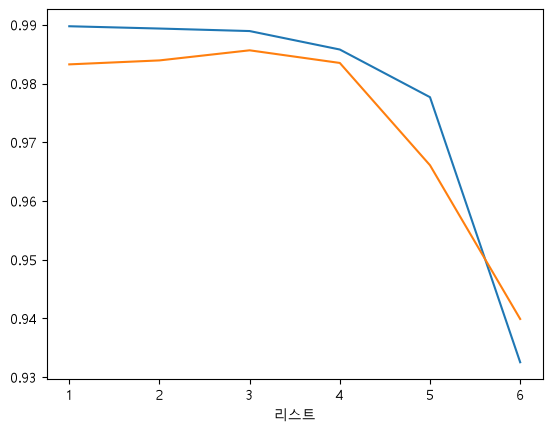

In [53]:
list = [1,2,3,4,5,6]

plt.plot(list,train_score)
plt.plot(list,test_score)
plt.xlabel('리스트')

In [54]:
# 데이터 학습
ridge =Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

# 데이터 예측
predict = ridge.predict(test_scaled)

# 정확도
scor = ridge.score(train_scaled,train_label)
scor2 = ridge.score(test_scaled,test_label)
scor,scor2

(0.9857915060511934, 0.9835057194929058)